In [1]:

import pandas as pd

# Load the five CSV files
production = pd.read_csv('/content/production.csv')
machines = pd.read_csv('/content/machines.csv')
materials = pd.read_csv('/content/materials.csv')
process = pd.read_csv('/content/process.csv')
inspection = pd.read_csv('/content/inspection.csv')

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [2]:

print("Production:", production.shape)
print("Machines:", machines.shape)
print("Materials:", materials.shape)
print("Process:", process.shape)
print("Inspection:", inspection.shape)


Production: (303, 6)
Machines: (12, 3)
Materials: (60, 3)
Process: (300, 4)
Inspection: (1366, 4)


In [3]:


# Display the first 5 rows of each dataset
print("PRODUCTION DATA")
display(production.head())

print("MACHINES DATA")
display(machines.head())

print("MATERIALS DATA")
display(materials.head())

print("PROCESS DATA")
display(process.head())

print("INSPECTION DATA")
display(inspection.head())


PRODUCTION DATA


,batch,line,shift,quantity,machine,lot
0,B1001,Line B,Morning,272,M06,L2042
1,B1002,Line B,Night,413,M06,L2044
2,B1003,Line C,Morning,231,M09,L2057
3,B1004,Line B,Evening,246,M06,L2058
4,B1005,Line C,Morning,173,M09,L2008


MACHINES DATA


,machine,age_band,operating_hours
0,M01,Old,2409
1,M02,New,3531
2,M03,New,15932
3,M04,Mid-age,12227
4,M05,New,5235


MATERIALS DATA


,supplier,material_grade,lot
0,Vertex Supply,Grade B,L2001
1,Northstar Metals,Grade B,L2002
2,Apex Materials,Grade A,L2003
3,Northstar Metals,Grade C,L2004
4,Prime Alloy Co,Grade A,L2005


PROCESS DATA


,batch,temperature,pressure,speed
0,B1001,197.55,4.70,114.46
1,B1002,199.42,5.44,95.79
2,B1003,176.57,6.51,108.30
3,B1004,177.49,4.57,95.98
4,B1005,189.11,4.23,100.72


INSPECTION DATA


,batch,defect_type,defect_count,quality_status
0,B1001,surface crack,26,Fail
1,B1001,Dimension Error,24,Fail
2,B1001,Porosity,13,Fail
3,B1001,Contamination,6,Fail
4,B1001,Other,11,Fail


In [4]:

datasets = {
    "Production": production,
    "Machines": machines,
    "Materials": materials,
    "Process": process,
    "Inspection": inspection
}

for name, df in datasets.items():
    print("\n---", name, "---")
    print("Data types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())



--- Production ---
Data types:
batch       object
line        object
shift       object
quantity     int64
machine     object
lot         object
dtype: object

Missing values:
batch       0
line        0
shift       0
quantity    0
machine     0
lot         0
dtype: int64

Duplicate rows: 3

--- Machines ---
Data types:
machine            object
age_band           object
operating_hours     int64
dtype: object

Missing values:
machine            0
age_band           0
operating_hours    0
dtype: int64

Duplicate rows: 0

--- Materials ---
Data types:
supplier          object
material_grade    object
lot               object
dtype: object

Missing values:
supplier          0
material_grade    0
lot               0
dtype: int64

Duplicate rows: 0

--- Process ---
Data types:
batch           object
temperature    float64
pressure       float64
speed          float64
dtype: object

Missing values:
batch          0
temperature    8
pressure       4
speed          3
dtype: int64

Duplicate 

In [7]:

# Check duplicates before removing them
print("Production duplicates:", production.duplicated().sum())
print("Machines duplicates:", machines.duplicated().sum())
print("Materials duplicates:", materials.duplicated().sum())
print("Process duplicates:", process.duplicated().sum())
print("Inspection duplicates:", inspection.duplicated().sum())

# Remove exact duplicate rows
production = production.drop_duplicates()
machines = machines.drop_duplicates()
materials = materials.drop_duplicates()
process = process.drop_duplicates()
inspection = inspection.drop_duplicates()

print("\nDuplicate rows removed!")

print("\n Missing values")
for name, df in datasets.items():
    print("\n", name)
    print(df.isnull().sum())


Production duplicates: 0
Machines duplicates: 0
Materials duplicates: 0
Process duplicates: 0
Inspection duplicates: 0

Duplicate rows removed!

 Production
batch       0
line        0
shift       0
quantity    0
machine     0
lot         0
dtype: int64

 Machines
machine            0
age_band           0
operating_hours    0
dtype: int64

 Materials
supplier          0
material_grade    0
lot               0
dtype: int64

 Process
batch          0
temperature    8
pressure       4
speed          3
dtype: int64

 Inspection
batch             0
defect_type       0
defect_count      0
quality_status    0
dtype: int64


In [8]:

# Fill missing process measurements using each column's median
process["temperature"] = process["temperature"].fillna(
    process["temperature"].median()
)

process["pressure"] = process["pressure"].fillna(
    process["pressure"].median()
)

process["speed"] = process["speed"].fillna(
    process["speed"].median()
)

print("Missing values after cleaning:")
print(process.isnull().sum())


Missing values after cleaning:
batch          0
temperature    0
pressure       0
speed          0
dtype: int64


In [11]:

print("PROCESS DATA STATISTICS")
display(process[["temperature", "pressure", "speed"]].describe())


PROCESS DATA STATISTICS


,temperature,pressure,speed
count,300.000000,300.000000,300.000000
mean,186.093100,5.142000,101.315667
std,20.648001,0.665874,11.142184
min,35.000000,3.430000,66.020000
25%,177.485000,4.655000,93.915000
50%,185.730000,5.190000,101.400000
75%,193.235000,5.630000,108.312500
max,410.000000,6.830000,131.320000


In [13]:

# Detect outliers in temperature, pressure, and speed

columns = ["temperature", "pressure", "speed"]

for col in columns:
    Q1 = process[col].quantile(0.25)
    Q3 = process[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = process[
        (process[col] < lower_limit) |
        (process[col] > upper_limit)
    ]

    print(f"\n{col}")
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Number of outliers:", len(outliers))



temperature
Lower limit: 153.86000000000007
Upper limit: 216.85999999999996
Number of outliers: 4

pressure
Lower limit: 3.192500000000001
Upper limit: 7.092499999999999
Number of outliers: 0

speed
Lower limit: 72.31874999999998
Upper limit: 129.90875
Number of outliers: 3


In [15]:

# Start with production data
combined = production.copy()

# Add process measurements using batch number
combined = combined.merge(
    process,
    on="batch",
    how="left"
)

# Add machine information using machine ID
combined = combined.merge(
    machines,
    on="machine",
    how="left"
)

# Add supplier and material information using lot number
combined = combined.merge(
    materials,
    on="lot",
    how="left"
)

# Add inspection records using batch number
combined = combined.merge(
    inspection,
    on="batch",
    how="left"
)

print("Combined dataset shape:", combined.shape)
display(combined.head())


Combined dataset shape: (1391, 16)


,batch,line,shift,quantity,machine,lot,temperature,pressure,speed,age_band,operating_hours,supplier,material_grade,defect_type,defect_count,quality_status
0,B1001,Line B,Morning,272,M06,L2042,197.55,4.7,114.46,Mid-age,7979,Vertex Supply,Grade A,surface crack,26.0,Fail
1,B1001,Line B,Morning,272,M06,L2042,197.55,4.7,114.46,Mid-age,7979,Vertex Supply,Grade A,Dimension Error,24.0,Fail
2,B1001,Line B,Morning,272,M06,L2042,197.55,4.7,114.46,Mid-age,7979,Vertex Supply,Grade A,Porosity,13.0,Fail
3,B1001,Line B,Morning,272,M06,L2042,197.55,4.7,114.46,Mid-age,7979,Vertex Supply,Grade A,Contamination,6.0,Fail
4,B1001,Line B,Morning,272,M06,L2042,197.55,4.7,114.46,Mid-age,7979,Vertex Supply,Grade A,Other,11.0,Fail


In [16]:

# Calculate total defects for each batch
batch_defects = (
    inspection.groupby("batch")["defect_count"]
    .sum()
    .reset_index()
)

batch_defects.rename(
    columns={"defect_count": "total_defects"},
    inplace=True
)

display(batch_defects.head())


,batch,total_defects
0,B1001,80
1,B1002,103
2,B1003,70
3,B1004,59
4,B1005,52


In [18]:

# Attach total defects to production data
analysis_df = production.merge(
    batch_defects,
    on="batch",
    how="left"
)

# Batches without inspection records are marked as 0 for this practice dataset
analysis_df["total_defects"] = (
    analysis_df["total_defects"].fillna(0)
)

# Create a new feature
analysis_df["defect_rate"] = (
    analysis_df["total_defects"]
    / analysis_df["quantity"]
) * 100

print(analysis_df[
    ["batch", "quantity", "total_defects", "defect_rate"]
].head())


   batch  quantity  total_defects  defect_rate
0  B1001       272           80.0    29.411765
1  B1002       413          103.0    24.939467
2  B1003       231           70.0    30.303030
3  B1004       246           59.0    23.983740
4  B1005       173           52.0    30.057803


In [20]:

# Calculate defect rate for each production line
line_analysis = (
    analysis_df.groupby("line")
    .agg(
        total_production=("quantity", "sum"),
        total_defects=("total_defects", "sum")
    )
    .reset_index()
)

line_analysis["defect_rate"] = (
    line_analysis["total_defects"]
    / line_analysis["total_production"]
) * 100

line_analysis = line_analysis.sort_values(
    "defect_rate", ascending=False
)

display(line_analysis)


,line,total_production,total_defects,defect_rate
2,Line C,20172,5018.0,24.876066
0,Line A,21307,5296.0,24.855681
3,Line D,22161,5204.0,23.482695
1,Line B,24799,5591.0,22.545264


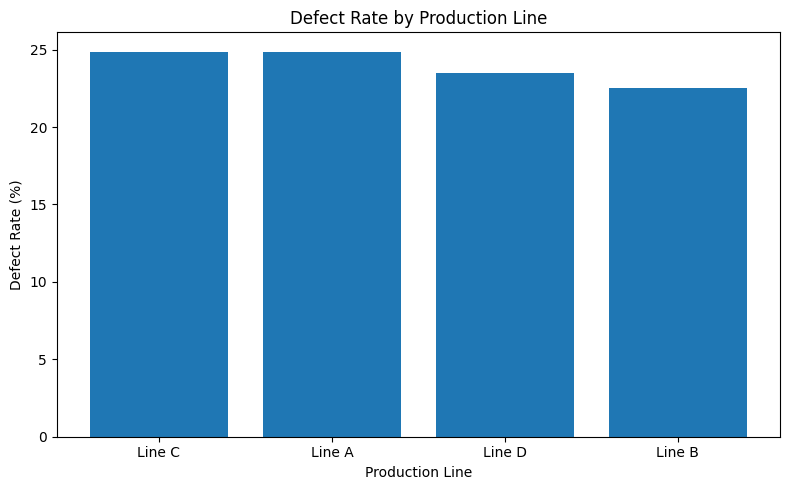

In [22]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    line_analysis["line"],
    line_analysis["defect_rate"]
)

plt.xlabel("Production Line")
plt.ylabel("Defect Rate (%)")
plt.title("Defect Rate by Production Line")
plt.tight_layout()
plt.show()


In [24]:

# Group defects by type and calculate total counts
defect_analysis = (
    inspection.groupby("defect_type")["defect_count"]
    .sum()
    .reset_index()
    .sort_values("defect_count", ascending=False)
)

display(defect_analysis)


,defect_type,defect_count
1,Dimension Error,5789
5,Surface Crack,5563
4,Porosity,4401
0,Contamination,3143
3,Other,2168
6,surface crack,26
2,Dimension error,19


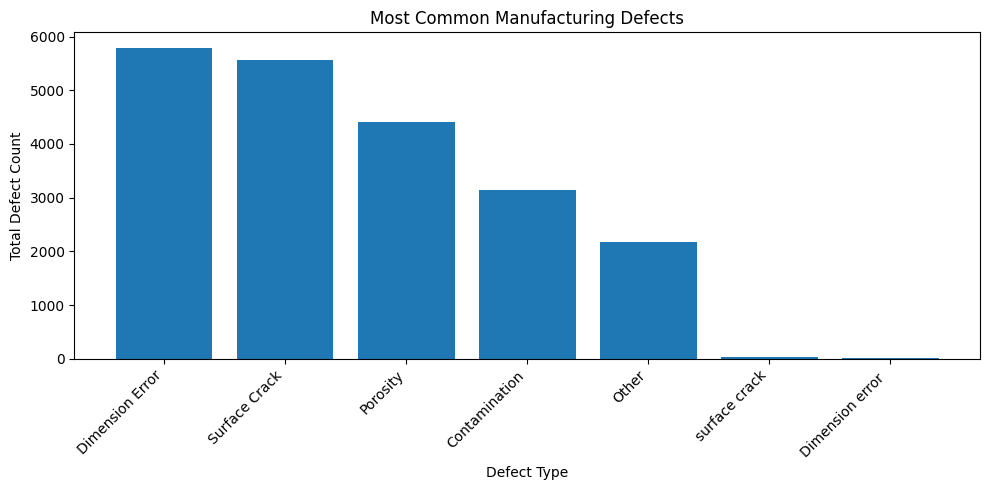

In [26]:

plt.figure(figsize=(10, 5))

plt.bar(
    defect_analysis["defect_type"],
    defect_analysis["defect_count"]
)

plt.xlabel("Defect Type")
plt.ylabel("Total Defect Count")
plt.title("Most Common Manufacturing Defects")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [28]:

shift_analysis = (
    analysis_df.groupby("shift")
    .agg(
        total_production=("quantity", "sum"),
        total_defects=("total_defects", "sum")
    )
    .reset_index()
)

shift_analysis["defect_rate"] = (
    shift_analysis["total_defects"]
    / shift_analysis["total_production"]
) * 100

display(shift_analysis.sort_values("defect_rate", ascending=False))


,shift,total_production,total_defects,defect_rate
2,Night,23589,5701.0,24.168044
1,Morning,32445,7805.0,24.056095
0,Evening,32405,7603.0,23.462429


In [30]:

# Add process measurements to the batch-level analysis
process_analysis = analysis_df.merge(
    process,
    on="batch",
    how="left"
)

# Compare average process readings for different defect rates
display(
    process_analysis[
        ["temperature", "pressure", "speed", "defect_rate"]
    ].corr()
)


,temperature,pressure,speed,defect_rate
temperature,1.000000,-0.004778,-0.049044,-0.021371
pressure,-0.004778,1.000000,0.057156,-0.017993
speed,-0.049044,0.057156,1.000000,-0.031038
defect_rate,-0.021371,-0.017993,-0.031038,1.000000


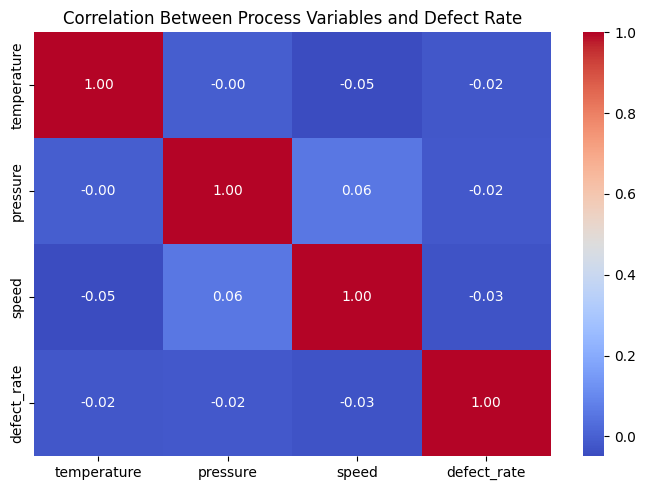

In [32]:

import seaborn as sns
import matplotlib.pyplot as plt

corr = process_analysis[
    ["temperature", "pressure", "speed", "defect_rate"]
].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Process Variables and Defect Rate")
plt.tight_layout()
plt.show()


In [34]:

# Combine production batches with supplier information
supplier_data = production.merge(
    materials,
    on="lot",
    how="left"
)

# Add total defects for each batch
supplier_data = supplier_data.merge(
    batch_defects,
    on="batch",
    how="left"
)

supplier_data["total_defects"] = (
    supplier_data["total_defects"].fillna(0)
)

# Calculate defect rate for each supplier
supplier_analysis = (
    supplier_data.groupby("supplier")
    .agg(
        total_production=("quantity", "sum"),
        total_defects=("total_defects", "sum")
    )
    .reset_index()
)

supplier_analysis["defect_rate"] = (
    supplier_analysis["total_defects"]
    / supplier_analysis["total_production"]
) * 100

display(
    supplier_analysis.sort_values(
        "defect_rate", ascending=False
    )
)


,supplier,total_production,total_defects,defect_rate
3,Vertex Supply,20269,4993.0,24.633677
2,Prime Alloy Co,19362,4647.0,24.000620
0,Apex Materials,25199,5913.0,23.465217
1,Northstar Metals,23127,5418.0,23.427163


In [36]:

machine_data = production.merge(
    machines,
    on="machine",
    how="left"
)

machine_data = machine_data.merge(
    batch_defects,
    on="batch",
    how="left"
)

machine_data["total_defects"] = (
    machine_data["total_defects"].fillna(0)
)

machine_analysis = (
    machine_data.groupby("age_band")
    .agg(
        total_production=("quantity", "sum"),
        total_defects=("total_defects", "sum"),
        average_operating_hours=("operating_hours", "mean")
    )
    .reset_index()
)

machine_analysis["defect_rate"] = (
    machine_analysis["total_defects"]
    / machine_analysis["total_production"]
) * 100

display(machine_analysis)


,age_band,total_production,total_defects,average_operating_hours,defect_rate
0,Mid-age,40349,9562.0,8881.405797,23.698233
1,New,21808,4624.0,7519.533333,21.203228
2,Old,26282,6923.0,6960.494253,26.341222


In [37]:

# Save each cleaned dataset as a CSV file
production.to_csv("cleaned_production.csv", index=False)
machines.to_csv("cleaned_machines.csv", index=False)
materials.to_csv("cleaned_materials.csv", index=False)
process.to_csv("cleaned_process.csv", index=False)
inspection.to_csv("cleaned_inspection.csv", index=False)

# Save the combined analysis dataset
analysis_df.to_csv("manufacturing_quality_analysis.csv", index=False)

print("All cleaned datasets and analysis data saved!")


All cleaned datasets and analysis data saved!


In [38]:

from google.colab import files

files.download("manufacturing_quality_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>